# DisCell on a public Xenium section (lung cancer FFPE)

This notebook runs DisCell on one public 10x Genomics section, image-free, with one κ and one
seed:

ingest → lineage labels → cell graph → fit → probe → relocation.

**Data.** *Xenium Prime FFPE Human Lung Cancer* (10x Genomics, 5K Human Pan Tissue and
Pathways Panel), licensed CC BY 4.0. All maps and plots below are derived from this dataset;
credit 10x Genomics when you reuse them. The section has about 278,000 cells and 5,000 genes.

**Download** (22.6 GB zip, about the same again unpacked), from the repository root:

```bash
bash reproduce/download.sh lung_ffpe data/
```

This fetches `https://cf.10xgenomics.com/samples/xenium/3.0.0/Xenium_Prime_Human_Lung_Cancer_FFPE/Xenium_Prime_Human_Lung_Cancer_FFPE_outs.zip`
and unpacks it into `data/Xenium_Prime_Human_Lung_Cancer_FFPE/`. The notebook looks for it
under `../data/` (relative to `examples/`); set the environment variable `DISCELL_DATA` to
use another folder.

**Hardware and time.** One RTX 4090 GPU: about 4 minutes in total, of which the fit takes
about 2. Peak host memory: about 7 GB. On a smaller GPU, or to try things quickly, read only a
region: `dc.read_xenium(OUTS, region_um=(x0, y0, x1, y1))` (micrometers). A small region
gives fewer and noisier niche pairs.

**The image add-on.** DisCell can add an image descriptor of the tissue around each cell, from
the KRONOS2 model (MahmoodLab). Its weights are gated and licensed for non-commercial academic
use only. Request access at <https://huggingface.co/MahmoodLab/KRONOS2>, then
`pip install "discell[image]"` (Python 3.11 or newer), log in with `hf auth login`, and run
`discell.image.embed(adata)` before fitting. Embedding this section takes about an hour on one
GPU. Then pass `image_key="X_kronos_masked"` to `dc.Config`. This notebook stays image-free.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import discell as dc

plt.rcParams["figure.dpi"] = 80
DATA = Path(os.environ.get("DISCELL_DATA", "../data"))
OUTS = DATA / "Xenium_Prime_Human_Lung_Cancer_FFPE"
LINEAGE_MAP = Path("../reproduce/labels/lung_ffpe/lineage_map.csv")
assert (OUTS / "experiment.xenium").exists(), "download the section first (see above)"
started = time.time()

## 1. Ingest

`dc.read_xenium` reads the raw counts, takes each cell's centroid from its segmented boundary,
and attaches 10x's own clusterings from the `analysis/` folder (here `graphclust`).

In [2]:
adata = dc.read_xenium(OUTS, labels=None)
print(f"{adata.n_obs:,} cells x {adata.n_vars:,} genes")

278,324 cells x 5,001 genes


## 2. Lineage labels

DisCell needs one type label per cell. We use the lineage map shipped in
`reproduce/labels/lung_ffpe/`, the labels of the paper. It sends each 10x `graphclust` cluster
to a lineage (cell states and locations merged into their lineage). Cells without a cluster
become `Unassigned`. They stay in the graph and in training but are never graded.

In [3]:
lineage_map = pd.read_csv(LINEAGE_MAP)
to_lineage = dict(zip(lineage_map["source_label"], lineage_map["lineage"]))
lineage = adata.obs["graphclust"].astype(object).map(to_lineage).fillna("Unassigned")
adata.obs["lineage"] = pd.Categorical(lineage.astype(str))
adata.obs["lineage"].value_counts().to_frame("cells").T

lineage,Tumour,T/NK cells,EC general capillary,Adventitial fibroblasts,Interstitial macrophages,Smooth muscle,Neutrophils,Alveolar fibroblasts,AT1,B cells,EC venous,Plasma cells,Alveolar macrophages,Goblet,AT2,Multiciliated,Pericytes,Mast cells,Neuroendocrine,Unassigned
cells,45646,45287,29431,24835,21479,16446,15040,10985,10613,9409,8602,8300,7591,6177,6081,4999,4161,2404,656,182


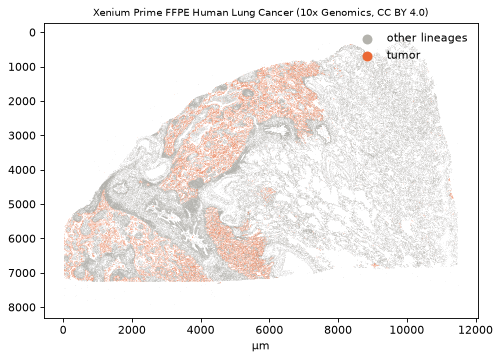

In [4]:
xy = adata.obsm["spatial"]
tumor = (adata.obs["lineage"] == "Tumour").to_numpy()
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(xy[~tumor, 0], xy[~tumor, 1], s=0.05, color="#b4b3ad", lw=0, rasterized=True,
           label="other lineages")
ax.scatter(xy[tumor, 0], xy[tumor, 1], s=0.05, color="#eb6834", lw=0, rasterized=True,
           label="tumor")
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_xlabel("µm")
ax.legend(markerscale=40, frameon=False, loc="upper right")
ax.set_title("Xenium Prime FFPE Human Lung Cancer (10x Genomics, CC BY 4.0)", fontsize=9);

## 3. Graph and fit

`dc.build_graph` connects cells whose Voronoi regions (clipped to 30 µm) share a face, drops
edges longer than 40 µm, and computes the spillover weights β and each cell's neighbor
composition.

The fit uses the paper's settings (the defaults of `dc.Config`) at the operating point
κ = 0.1. `alpha_z` is the paper's value for this section. The default `"auto"` sets it from
the section's median count and gives a similar value. `image_key=None` fits the image-free
model: the niche descriptor is then the neighbor composition only.

κ = 0.1 is a working assumption, not an estimate. Before you trust a finding, read it along a
sweep (`dc.sensitivity.fit_sweep`, then `fit_draws` and `finding_breakdown`; see
[01_quickstart_simulated.ipynb](01_quickstart_simulated.ipynb) and
[docs/use_cases.md](../docs/use_cases.md)). A full sweep is 18 fits.

In [5]:
dc.build_graph(adata, "lineage")
config = dc.Config(label_key="lineage", image_key=None, kappa=0.1, seed=0, alpha_z=0.002,
                   device="cuda")
model = dc.fit(adata, config)
s = model.summary()
print(f"fit in {model.metrics['minutes']:.1f} min, best epoch {s['best_epoch']}")
print(f"held-out reconstruction {s['recon_val']:.3f} nats per count, NMI of z with lineage "
      f"{s['nmi']:.2f}")
print(f"niche information in w above its permutation baseline {s['niche_information_check']:.2f} nats"
      f"; dead context channel: {s['dead_context_channel']}")

fit in 2.4 min, best epoch 39
held-out reconstruction -7.230 nats per count, NMI of z with lineage 0.70
niche information in w above its permutation baseline 0.77 nats; dead context channel: False


## 4. The probe

How much niche information is left in the intrinsic state z? A linear and a nonlinear
probe predict each cell's neighbor composition from z and its type on held-out tiles.
The neighborhood information is their skill beyond the type alone and beyond z shuffled within
type, roughly as a share of the within-type variance.

In [6]:
probe = dc.evaluate.heldout_probe(model, adata)
for grader, name in (("ridge", "linear"), ("mlp", "nonlinear")):
    block = probe[grader]["comp"]
    print(f"{name:9s} probe: neighborhood information {100 * block['var_fraction']:.1f}% "
          f"(gain {block['gain']:.4f}, permutation baseline {block['floor_mean']:.4f})")

linear    probe: neighborhood information 0.6% (gain 0.0011, permutation baseline -0.0020)
nonlinear probe: neighborhood information 3.5% (gain -0.0003, permutation baseline -0.0183)


## 5. Relocation

Relocation asks: if the cells of one type sat in another niche, how would their mean
expression change? DisCell keeps each cell's intrinsic state z, moves the prior of its response
and its spillover influx to the target niche, and decodes. Niches are 10 k-means clusters of
the neighbor composition. A *niche pair* is one type and two niches. For each pair the
predicted per-gene shift is scored (R²) against the observed shift, on a spatial fold that
the model quantities of the prediction do not come from (the model itself was fitted on most
of these cells). Three predictions are scored:

* `predicted`: response and spillover decoded together, the model's full account of the move;
* `response`: the response part alone;
* `spillover`: the spillover part alone.

The *noise ceiling* is how well two random halves of the cells reproduce the observed shift.
No predictor can do better. A pair is *trusted* when its ceiling is at least 0.5 on at least
100 genes. Pairs are *supported* when the two niches overlap in composition for that type,
and *extrapolation* otherwise (almost all, with k-means niches).

In [7]:
rel = dc.tl.relocation(model, adata)
rows = {tier: {key: summary[key] for key in
               ("n_pairs", "predicted", "response", "spillover", "noise_ceiling",
                "fraction_of_ceiling")}
        for tier, summary in rel["summary"].items()}
pd.DataFrame(rows).T.round(3)

,n_pairs,predicted,response,spillover,noise_ceiling,fraction_of_ceiling
supported,16.0,0.018,0.017,0.009,0.034,NaN
extrapolation,128.0,0.157,0.119,0.077,0.168,0.933
extrapolation_trusted,10.0,0.437,0.329,0.225,0.566,0.771
extrapolation_trusted_tiles,8.0,0.448,0.327,0.238,0.580,0.773


In [8]:
trusted = [p for p in rel["pairs"] if p["trusted"]]
pd.DataFrame([{"type": p["type"], "niches": tuple(p["niches"]), "genes": p["n_genes"],
               "ceiling": p["noise_ceiling"], "predicted": p["predicted"]["r2"],
               "response": p["response"]["r2"], "spillover": p["spillover"]["r2"]}
              for p in trusted]).round(3)

,type,niches,genes,ceiling,predicted,response,spillover
0,Interstitial macrophages,"(1, 8)",3357,0.561,0.412,0.318,0.203
1,T/NK cells,"(1, 8)",3387,0.629,0.505,0.430,0.234
2,Interstitial macrophages,"(6, 8)",3321,0.513,0.401,0.360,0.161
3,T/NK cells,"(6, 8)",3310,0.530,0.414,0.357,0.194
4,T/NK cells,"(2, 8)",3325,0.602,0.496,0.412,0.233
5,T/NK cells,"(8, 9)",3395,0.537,0.425,0.364,0.179
6,Interstitial macrophages,"(1, 4)",3420,0.505,0.379,0.305,0.178
7,T/NK cells,"(1, 4)",3494,0.555,0.438,0.383,0.194
8,T/NK cells,"(2, 4)",3440,0.561,0.424,0.357,0.197
9,Tumour,"(3, 6)",3341,0.666,0.472,-0.002,0.473


How to read relocation, and its limits:

* Compare each R² with the pair's ceiling, not with 1.
* The observed shift contains spillover, so this score cannot show that separating response
  from spillover helps. On cells withheld from training (the paper's Fig. 7), a ridge
  regression of the shifts on neighbor composition had the lowest error on five of nine tasks,
  but it moves no cells and keeps spillover in its prediction.
* At the default weights the response is type-level: it describes how a type shifts with its
  niche, not how one cell deviates from its type's expectation.
* Relocation is a read at one κ. The relocation finding (`relocation_finding`) is one of the
  paper's findings, so a sweep gives it a breakdown point. Two comparisons of moved cells
  (`moved_vs_type_mean`, `moved_vs_random_cell`) enter the Bonferroni correction but are not
  reported.

## Save

`adata.write_h5ad("lung_discell.h5ad")` keeps every output (latents, loadings, the
readout records in `.uns["discell"]`); `model.save("fits/k0.1_s0")` keeps the model.

In [9]:
print(f"total {(time.time() - started) / 60:.1f} min")

total 3.1 min
